In [1]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time

<div dir="rtl">

## Rounting - ניתוב

### יש לנו זרם הגעה ואנחנו צריכים לבחור לאן לשלוח צרכנים.

### נבדוק מה ההבדל בין 2 אסטרטגיות:

### 1. לשלוח אקראית ל-2 התחנות
### 2. לשלוח לתור הקצר ביותר

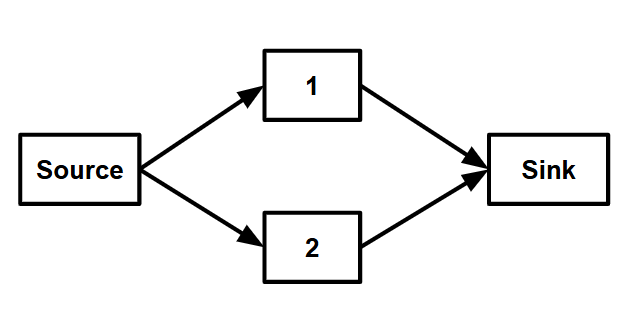

In [17]:
Image('../Images/join_shortest_queue_2_staitons.png', width=620)

In [38]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time


# part 1
arrival_rate = 3.8
service_rates = np.array([2, 2])
sim_time = 50000


## Defining a new class: of customers
# part 5
class Customer:
    def __init__(self, p_id, arrival_time):
        self.id = p_id
        self.arrival_time = arrival_time


class Queue_two_stations_markov_trans:

    ###########################################################################
    ###########################################################################
    def __init__(self, arrival_rates, service_rates,  sim_time, routing):

        #####################################################
        # 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        self.routing = routing
        #################################################
        #####################################################################################
        # part 3
        ## defining resources
        self.server = []
        for station in range(2):
            ## Defining the servers
            self.server.append(simpy.Resource(self.env, capacity=1))  # Defining a resource with capacity 1

        ## Defining the customers arrivals

        self.env.process(self.customer_arrivals())  ## Initializing a process

        #####################################################################################
        # part 4
        #####################################################################################
        ## For keeping track on the number of customers in the system
        self.num_cust_durations = []
        self.last_event_time = []  # the time of the last event -
        self.num_cust_sys = []  # keeping track of number of customers in the system
        ####################################

        self.sojourn_times = {}
        for station in range(2):
            self.sojourn_times[station] = []

            ##
            self.num_cust_durations.append(
                np.zeros(5000))  ## the time duration of each each state (state= number of cusotmers in the system)
        ##############################################################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id

    ########################################################################################
    ########################################################################################

    #########################################################
    ################# Arrival block #########################
    #########################################################

    # 6

    def customer_arrivals(self, ):

        while True:
            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time)
            self.id_current += 1
            queue_lenght_station_0 = len(self.server[0].queue ) + self.server[0].count
            queue_lenght_station_1 = len(self.server[1].queue ) + self.server[1].count


            # Join the shortest queue:

            if self.routing == 'shortest_queue':
            
                if queue_lenght_station_0 == queue_lenght_station_1:
                    station = np.random.randint(0,2)
                elif queue_lenght_station_0 < queue_lenght_station_1:
                    station = 0
                else:
                    station = 1

            else:
                
                if np.random.rand() < 0.5:
                    station = 0
                else:
                    station  = 1

           


            self.env.process(self.service(customer, station))

    #########################################################
    ################# Service block #########################
    #########################################################
    # part 7
    def service(self, customer, station):
        with self.server[station].request() as req:
            # requesting service - meanwhile waiting in line
            yield req

            # Startng service
            yield self.env.timeout(np.random.exponential(1 / self.service_rates[station]))
            #####################################################################
            # part 8
            self.sojourn_times[station].append(self.env.now - customer.arrival_time)
            ######################################################################

        # ## next station - if 2 means exit the system:
        # all_probs = np.append(self.probs[station], 1 - self.probs[station].sum())
        # next_station = np.random.choice(3, 1, p=all_probs).item()
        #
        # if next_station < self.probs.shape[0]:
        #     customer.arrival_time = self.env.now
        #     self.env.process(self.service(customer, next_station))

    #########################################################################################
    # 9
    ### Running the simulation
    def run(self):
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
##########################################################################################




<div dir="rtl">

## נשווה בין 2 אופציות - פעם אחת היא להצטרף לתור הקצר ביותר.

## פעם אחרת פשוט נשלח את הצרכנים אקראית

In [39]:
queue_two_stations_markov_trans = Queue_two_stations_markov_trans(arrival_rate, service_rates,  sim_time, 'shortest_queue')
queue_two_stations_markov_trans.run()

print(np.array(queue_two_stations_markov_trans.sojourn_times[0]).mean(), np.array(queue_two_stations_markov_trans.sojourn_times[1]).mean())

Starting simulating two stations system...
Simulation end
5.504725112694282 5.468328357542499


In [40]:
queue_two_stations_markov_trans = Queue_two_stations_markov_trans(arrival_rate, service_rates,  sim_time, 'random')
queue_two_stations_markov_trans.run()

print(np.array(queue_two_stations_markov_trans.sojourn_times[0]).mean(), np.array(queue_two_stations_markov_trans.sojourn_times[1]).mean())

Starting simulating two stations system...
Simulation end
10.48468663846676 8.966162625105127


<div dir="rtl">

## איך שולחים לתור הקצר ביותר?

### נרצה לדעת מה אורך התור הנוכחי.

### בשביל זה נתמש בפקודה הבאה:

## len(self.server[0].queue)

## בעצם הattribute .queue נותן לנו רשימה של כל מי שנמצא בתור והאורך של הרשימה נותן לנו את אורך התור

### זה נותן לנו את אורך התור של השרת הראשון

### אבל זה נותן לנו רק את אורך התור. נניח כי יש שני שרתים בלי תור אבל אחד מהם עסוק והשני בבטלה. כמובן נרצה לשלוח לתור בבטלה, לכן נרצה לדעת אם התור עסוק ברגע הכרעה. 

### בשביל זה נשתמש בפקודה:

## self.server[0].count

### נקבל 0 אם בבטלה ו-1 אם עסוק. אם נסכום את 

### len(self.server[0].queue) + self.server[0].count

### נקבל את כמות הצרכנים בתור + שירות 

## מבחינת חקר ביצועים נראה שבמקרה הזה לשלוח לתור הקצר ביותר טוב יותר מלשלוח אקראית.

### האם זו אסטרטגיה הכי טובה תמיד?

### יש עוד משהו שכדאי לנו לקחת בחשבון, כמה זמן ייקח למי שנמצא בשירות לסיים אותו.

### נניח כי 2 סוגי שירות:

## 1. שירות קבוע של 0.5 דקה.
## 2. שירות קצר בהתסברות גבוהה ושירות מאד מאד ארוך בהסתברות נמוכה.
### למטה בדוגמא: 49 דקות בהסתברות 0.01 
### או לחילופין: 0.01 בהסתברות של 0.99
### גם השירות השני הוא בממוצע 0.5 דקה.

## אם יוצא שיש לנו שירות ארוך והתחיל לפני 2 דקות אז נשאר לנו עוד 47 דקות עד שנסיים במקרה כזה נעדיף לשלוח לתור השני גם א הוא יותר ארוך

### בכל רגע נתון נרצה לדעת כמה זמן עבר מתחילת שירות לכן נגדיר את המילון:

### self.service_start_time 

### כאשר:

## self.service_start_time[0]

### מתייחס לזמן שהתחיל בשירות של השרת בזמן קבוע של 0.5 דקה

### ואילו:

## self.service_start_time[1]

### מתאר כמה זמן עבר תחילת השירות של השרת עם השונות הגבוהה. 


In [157]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time


# part 1
arrival_rate = 2.2
sim_time = 250000


## Defining a new class: of customers
# part 5
class Customer:
    def __init__(self, p_id, arrival_time):
        self.id = p_id
        self.arrival_time = arrival_time


class Queue_two_stations_shoert_queue_not_opt:

    ###########################################################################
    ###########################################################################
    def __init__(self, arrival_rates, service_rates,  sim_time, routing):

        #####################################################
        # 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        self.routing = routing
        ## monitrong the service age
        self.current_ser_age_0 = 0
        self.current_ser_age_1 = 0
        #################################################
        #####################################################################################
        # part 3
        ## defining resources
        self.server = []
        self.service_start_time = {}
        for station in range(2):
            ## Defining the servers
            self.server.append(simpy.Resource(self.env, capacity=1))  # Defining a resource with capacity 1
            self.service_start_time[station] = 0

        ## Defining the customers arrivals

        self.env.process(self.customer_arrivals())  ## Initializing a process

        #####################################################################################
        # part 4
        #####################################################################################
        ## For keeping track on the number of customers in the system
        self.num_cust_durations = []
        self.last_event_time = []  # the time of the last event -
        self.num_cust_sys = []  # keeping track of number of customers in the system
        ####################################

        self.sojourn_times = {}
        for station in range(2):
            self.sojourn_times[station] = []

            ##
            self.num_cust_durations.append(
                np.zeros(5000))  ## the time duration of each each state (state= number of cusotmers in the system)
        ##############################################################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id

    ########################################################################################
    ########################################################################################

    #########################################################
    ################# Arrival block #########################
    #########################################################

    # 6

    def customer_arrivals(self, ):

        while True:
            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time)
            self.id_current += 1
            queue_lenght_station_0 = len(self.server[0].queue ) + self.server[0].count
            queue_lenght_station_1 = len(self.server[1].queue ) + self.server[1].count

            self.current_ser_age_0 = self.env.now - self.service_start_time[0]
            self.current_ser_age_1 = self.env.now - self.service_start_time[1]
            

            # Join the shortest queue:

            if self.routing == 'shortest_queue':
            
                if queue_lenght_station_0 == queue_lenght_station_1:
                    station = np.random.randint(0,2)
                elif queue_lenght_station_0 < queue_lenght_station_1:
                    station = 0
                else:
                    station = 1

            else:

                if self.current_ser_age_1 > 20:
                    station = 0
                else:
                    
                    if queue_lenght_station_0 == queue_lenght_station_1:
                        station = np.random.randint(0,2)
                    elif queue_lenght_station_0 < queue_lenght_station_1:
                        station = 0
                    else:
                        station = 1

            self.env.process(self.service(customer, station))

    #########################################################
    ################# Service block #########################
    #########################################################
    # part 7
    def service(self, customer, station):
        with self.server[station].request() as req:
            # requesting service - meanwhile waiting in line
            yield req
            

            if station  == 0:
                ser_time = 0.5
            else:
                ser_time =  np.random.choice([49.01, 0.01], p=[0.01, 0.99])

            # updating the service age
            
            self.service_start_time[station] = self.env.now
            
            # Startng service
            
            yield self.env.timeout(ser_time)
            #####################################################################
            # part 8
            self.sojourn_times[station].append(self.env.now - customer.arrival_time)
            ######################################################################



    #########################################################################################
    # 9
    ### Running the simulation
    def run(self):
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
##########################################################################################




In [158]:
queue_two_stations_shoert_queue_not_opt = Queue_two_stations_shoert_queue_not_opt(arrival_rate, service_rates,  sim_time, 'shortest_queue')
queue_two_stations_shoert_queue_not_opt.run()
print('mean sojourn time under shortest queue:')
(np.array(queue_two_stations_shoert_queue_not_opt.sojourn_times[0]).mean() +  np.array(queue_two_stations_shoert_queue_not_opt.sojourn_times[1]).mean())/2

Starting simulating two stations system...
Simulation end
mean sojourn time under shortest queue:


np.float64(2.9438875692924853)

In [159]:
print('mean sojourn time under while considering serivce age:')

queue_two_stations_shoert_queue_not_opt = Queue_two_stations_shoert_queue_not_opt(arrival_rate, service_rates,  sim_time, 'age')
queue_two_stations_shoert_queue_not_opt.run()

(np.array(queue_two_stations_shoert_queue_not_opt.sojourn_times[0]).mean() +  np.array(queue_two_stations_shoert_queue_not_opt.sojourn_times[1]).mean())/2

mean sojourn time under while considering serivce age:
Starting simulating two stations system...
Simulation end


np.float64(2.873022203233469)

<div dir="rtl">

### לאחר הרצה של שתי שיטות הינתוב נראה שהshorstest queue מגיע עם תוחלת זמן שהייה יותר גדול

<div dir="rtl">

## נניח כי יש לכם קליניקה ובה אתם עושים 3 בדיקות של לקוחות: מסומן באיור למטה כ1,2 ו-3. 

### אין חשיבות לסדר אבל חשוב שכל אחד יגיע לכל אחד מהתחנות לפני שהוא עוזב את המערכת.

### נממש כך שכל פעם נבדוק אילו תחנות נשארו ללקוח ונשלח אותו אקראית מאותה רשימה

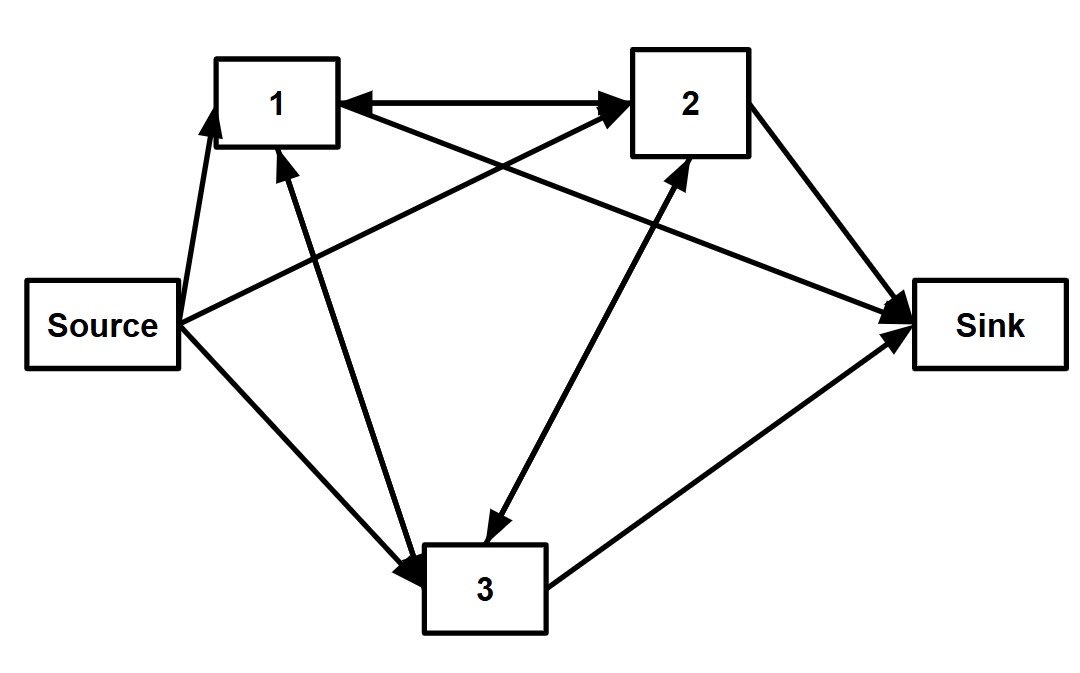

In [41]:

Image('../Images/ichilov_clinic.png', width=620)


In [5]:
# part 1
arrival_rate = 1.5
service_rates = np.array([2, 2, 2])
sim_time = 50000


In [6]:
## Defining a new class: of customers
# part 5
class Customer:
    def __init__(self, p_id, arrival_time):
        self.id = p_id
        self.arrival_time = arrival_time
        # all stations customets have not been in service yet
        self.remain_service = [0, 1, 2]


class Queue_three_stations_markov_trans:

    ###########################################################################
    ###########################################################################
    def __init__(self, arrival_rates, service_rates, sim_time):

        #####################################################
        # 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        #################################################
        #####################################################################################
        # part 3
        ## defining resources
        self.server = []
        for station in range(3):
            ## Defining the servers
            self.server.append(simpy.Resource(self.env, capacity=1))  # Defining a resource with capacity 1

        ## Defining the customers arrivals

        self.env.process(self.customer_arrivals())  ## Initializing a process

        #####################################################################################
        # part 4
        #####################################################################################
        ## For keeping track on the number of customers in the system
        self.num_cust_durations = []
        self.last_event_time = []  # the time of the last event -
        self.num_cust_sys = []  # keeping track of number of customers in the system
        ####################################

        self.sojourn_times = {}
        for station in range(3):
            self.sojourn_times[station] = []

            ##
            self.num_cust_durations.append(
                np.zeros(5000))  ## the time duration of each each state (state= number of cusotmers in the system)
        ##############################################################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id

    ########################################################################################
    ########################################################################################

    #########################################################
    ################# Arrival block #########################
    #########################################################

    # 6

    def customer_arrivals(self, ):

        while True:
            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time)
            self.id_current += 1




            station = np.random.choice(customer.remain_service)



            self.env.process(self.service(customer, station))

    #########################################################
    ################# Service block #########################
    #########################################################
    
    
    # part 7
    def service(self, customer, station):
        with self.server[station].request() as req:
            # requesting service - meanwhile waiting in line
            yield req

            # Startng service
            yield self.env.timeout(np.random.exponential(1 / self.service_rates[station]))

            # removing the station which service took place
            customer.remain_service.remove(station)
            #####################################################################
            # part 8

            if self.env.now > 10000:
                self.sojourn_times[station].append(self.env.now - customer.arrival_time)
            ######################################################################

        
        ## Send to next station only if there are services left
        if len(customer.remain_service) > 0:
        ## next station - if 2 means exit the system:
            next_station = np.random.choice(customer.remain_service)
            customer.arrival_time = self.env.now
            self.env.process(self.service(customer, next_station))




    #########################################################################################
    # 9
    ### Running the simulation
    def run(self):
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
##########################################################################################

<div dir="rtl">

# נריץ את הסימולציה ונחשב זמן שהייה בכל אחת מהמערכות

In [7]:
queue_three_stations_markov_trans = Queue_three_stations_markov_trans(arrival_rate, service_rates,  sim_time)
queue_three_stations_markov_trans.run()

mean_1_sojourn = np.array(queue_three_stations_markov_trans.sojourn_times[0]).mean()
mean_2_sojourn = np.array(queue_three_stations_markov_trans.sojourn_times[1]).mean()
mean_3_sojourn = np.array(queue_three_stations_markov_trans.sojourn_times[2]).mean()




print(mean_1_sojourn, mean_2_sojourn, mean_3_sojourn)

Starting simulating two stations system...
Simulation end
1.971905246782693 2.071238655530013 1.9497467411532114
